# 08 — Sad vs calm: a two-stage model and a pretrained audio model

Every model so far confuses Q3 (sad) and Q4 (calm): about a third of the songs of each are predicted as the other, and `05_spectrograms.ipynb` showed that their average spectra differ by less than half a decibel. After discussing the results, the coordinator asked for an attempt to reduce this confusion. Two steps were tried, each evaluated as before (choices on validation, test once, protocol A and the five artist splits):

1. **Two-stage model with our features** (`src/two_stage.py`). Stage 1: the CNN decides high vs low arousal, which it does well. Stage 2: a binary classifier trained only on the Q3 and Q4 training songs decides sad vs calm, from the top-k of the 155 hand-crafted features ranked by how well they separate Q3 from Q4 on the training set, optionally combined with the CNN's own Q3/Q4 opinion.
2. **Representations from a pretrained audio model** (`src/panns_embeddings.py`, `src/pretrained_experiments.py`). PANNs Cnn14 (Kong et al., 2020) is a CNN trained on AudioSet, about two million YouTube clips labelled with 527 sound classes, including the music-mood classes *Happy, Sad, Tender, Exciting, Angry, Scary* and *Funny music*. For every clip its 2,048-dimensional penultimate-layer output is extracted once and used, alone or with the 155 features, (a) by a four-class SVM or logistic regression, (b) fused with the CNN, and (c) as the sad/calm specialist in the two-stage model.

Tables and figures are saved to `results/pretrained/figures/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PRE = ROOT / "results" / "pretrained"
TWO = ROOT / "results" / "two_stage"
OUT = PRE / "figures"
OUT.mkdir(parents=True, exist_ok=True)
QUADRANTS = ["Q1", "Q2", "Q3", "Q4"]
NAMES = {"Q1": "Q1 happy", "Q2": "Q2 angry/tense", "Q3": "Q3 sad", "Q4": "Q4 calm"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})
summary = {}

two = pd.read_csv(TWO / "runs.csv")
pre = pd.read_csv(PRE / "runs.csv")
pre["model"] = pre["model"].replace({"panns_svm": "panns_alone", "panns_logreg": "panns_alone", "panns_tonal_svm": "panns_tonal_alone", "panns_tonal_logreg": "panns_tonal_alone"})
preds_pre = pd.read_csv(PRE / "test_predictions.csv", dtype={"Song": str})
preds_pre["model"] = preds_pre["model"].replace({"panns_svm": "panns_alone", "panns_logreg": "panns_alone", "panns_tonal_svm": "panns_tonal_alone", "panns_tonal_logreg": "panns_tonal_alone"})
preds_two = pd.read_csv(TWO / "test_predictions.csv", dtype={"Song": str})
all_runs = pd.concat([pre, two[two.model.isin(["selected", "two_stage_specialist_only"])].assign(model=lambda d: "features_" + d.model)])
all_preds = pd.concat([preds_pre, preds_two[preds_two.model.isin(["selected", "two_stage_specialist_only"])].assign(model=lambda d: "features_" + d.model)])
LABELS = {
    "cnn": "CNN (reference)",
    "features_selected": "step 1: two-stage, our features (selected on validation)",
    "features_two_stage_specialist_only": "step 1: two-stage, our features only",
    "panns_alone": "PANNs embedding + SVM/LR",
    "panns_tonal_alone": "PANNs + 155 features + SVM",
    "cnn_fusion_panns": "CNN + PANNs model",
    "cnn_fusion_panns_tonal": "CNN + (PANNs + 155 features) model",
    "two_stage_panns": "two-stage, PANNs specialist",
    "two_stage_panns_tonal": "two-stage, PANNs + features specialist",
}
ORDER = list(LABELS)

## 1. Results on unseen artists (mean over the five artist splits)

`sad_calm_accuracy` is the share of songs that are truly sad or calm **and** were put in the low-arousal half by the model, whose sad/calm label is correct; it isolates the sad-vs-calm decision from the arousal decision (chance = 0.5).

In [2]:
b = all_runs[all_runs.protocol != "A"].assign(q3_q4=lambda d: d.test_q3_as_q4 + d.test_q4_as_q3)
table = b.groupby("model").agg(macro_f1=("test_macro_f1", "mean"), sd=("test_macro_f1", "std"), accuracy=("test_accuracy", "mean"),
                               f1_Q3=("test_f1_Q3", "mean"), f1_Q4=("test_f1_Q4", "mean"), q3_q4_confusions=("q3_q4", "mean"),
                               sad_calm_accuracy=("test_sad_calm_accuracy_when_both_low", "mean")).loc[ORDER]
table.index = [LABELS[i] for i in table.index]
table.round(4).to_csv(OUT / "01_protocol_B.csv")
summary["B"] = table.round(4).to_dict(orient="index")
table.round(3)

,macro_f1,sd,accuracy,f1_Q3,f1_Q4,q3_q4_confusions,sad_calm_accuracy
CNN (reference),0.694,0.018,0.698,0.558,0.567,75.6,0.627
"step 1: two-stage, our features (selected on validation)",0.694,0.018,0.696,0.563,0.574,75.6,0.633
"step 1: two-stage, our features only",0.690,0.023,0.692,0.543,0.584,76.8,0.629
PANNs embedding + SVM/LR,0.697,0.012,0.701,0.555,0.579,72.0,0.639
PANNs + 155 features + SVM,0.711,0.020,0.714,0.585,0.592,68.8,0.658
CNN + PANNs model,0.710,0.026,0.715,0.588,0.589,69.6,0.654
CNN + (PANNs + 155 features) model,0.713,0.023,0.718,0.592,0.582,69.4,0.653
"two-stage, PANNs specialist",0.709,0.024,0.711,0.607,0.597,68.0,0.671
"two-stage, PANNs + features specialist",0.704,0.012,0.705,0.593,0.588,70.8,0.658


In [3]:
a = all_runs[all_runs.protocol == "A"].set_index("model").loc[ORDER][["test_macro_f1", "test_accuracy", "test_f1_Q3", "test_f1_Q4"]]
a.index = [LABELS[i] for i in a.index]
a.round(4).to_csv(OUT / "01_protocol_A.csv")
a.round(3)

,test_macro_f1,test_accuracy,test_f1_Q3,test_f1_Q4
CNN (reference),0.682,0.686,0.507,0.552
"step 1: two-stage, our features (selected on validation)",0.699,0.700,0.544,0.579
"step 1: two-stage, our features only",0.674,0.676,0.522,0.502
PANNs embedding + SVM/LR,0.718,0.717,0.667,0.582
PANNs + 155 features + SVM,0.726,0.725,0.675,0.599
CNN + PANNs model,0.678,0.682,0.514,0.546
CNN + (PANNs + 155 features) model,0.726,0.725,0.678,0.599
"two-stage, PANNs specialist",0.722,0.723,0.616,0.601
"two-stage, PANNs + features specialist",0.716,0.717,0.592,0.599


In [4]:
sel = pre[pre.model == "selected"][["protocol", "params", "weight_cnn", "val_macro_f1", "test_macro_f1"]]
sel.to_csv(OUT / "01_selected_per_split.csv", index=False)
summary["selected_per_split"] = sel.set_index("protocol")["params"].str.split(":").str[0].to_dict()
sel

,protocol,params,weight_cnn,val_macro_f1,test_macro_f1
7,A,"cnn_fusion_panns_tonal: {""C"": ""1"", ""gamma"": ""s...",0.3,0.747383,0.726162
15,B42,"cnn_fusion_panns_tonal: {""C"": ""1"", ""gamma"": ""0...",0.4,0.759294,0.704844
23,B43,"cnn_fusion_panns_tonal: {""C"": ""1"", ""gamma"": ""s...",0.4,0.762279,0.720586
31,B44,"cnn_fusion_panns_tonal: {""C"": ""1"", ""gamma"": ""s...",0.8,0.753914,0.681600
39,B45,"cnn_fusion_panns_tonal: {""C"": ""10"", ""gamma"": ""...",0.7,0.747376,0.745725
47,B46,"cnn_fusion_panns_tonal: {""C"": ""1"", ""gamma"": ""s...",0.3,0.763538,0.711566


## 2. Per split

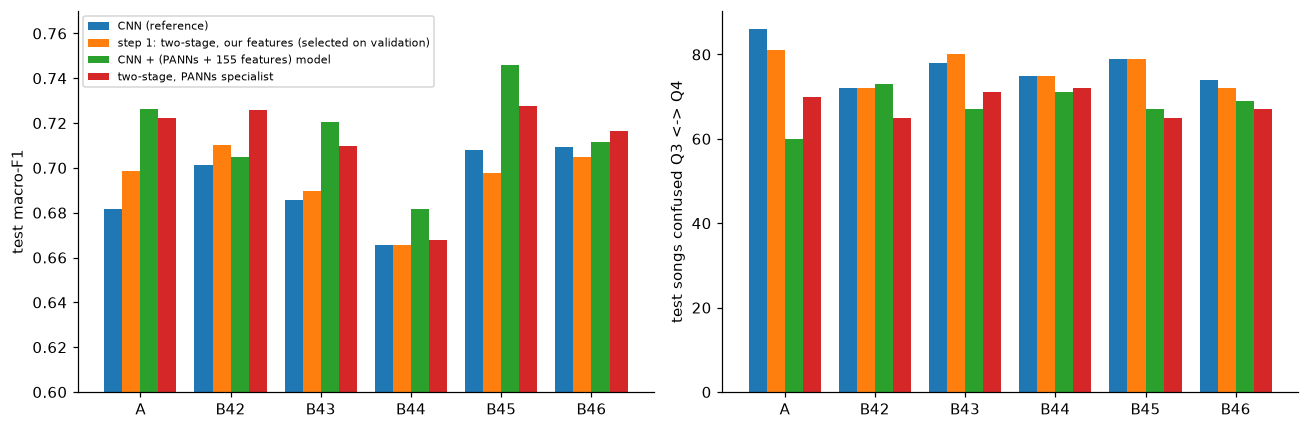

model,cnn,features_selected,cnn_fusion_panns_tonal,two_stage_panns
protocol,,,,
A,0.682,0.699,0.726,0.722
B42,0.701,0.710,0.705,0.726
B43,0.686,0.690,0.721,0.710
B44,0.665,0.665,0.682,0.668
B45,0.708,0.698,0.746,0.727
B46,0.709,0.705,0.712,0.716


In [5]:
show = ["cnn", "features_selected", "cnn_fusion_panns_tonal", "two_stage_panns"]
per = all_runs.pivot(index="protocol", columns="model", values="test_macro_f1")[show]
per.round(4).to_csv(OUT / "02_per_split.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(per))
for k, m in enumerate(show):
    axes[0].bar(x + (k - 1.5) * 0.2, per[m], 0.2, label=LABELS[m])
axes[0].set_xticks(x, per.index)
axes[0].set_ylim(0.6, 0.77)
axes[0].set_ylabel("test macro-F1")
axes[0].legend(fontsize=7)
q = all_runs.assign(q3_q4=lambda d: d.test_q3_as_q4 + d.test_q4_as_q3).pivot(index="protocol", columns="model", values="q3_q4")[show]
for k, m in enumerate(show):
    axes[1].bar(x + (k - 1.5) * 0.2, q[m], 0.2, label=LABELS[m])
axes[1].set_xticks(x, q.index)
axes[1].set_ylabel("test songs confused Q3 <-> Q4")
fig.tight_layout()
fig.savefig(OUT / "02_per_split.png", bbox_inches="tight")
plt.show()
per.round(3)

## 3. Significance (McNemar against the CNN)

Two comparisons per model: on all test songs (overall effect) and only on the songs that are truly sad or calm (effect on the confusion the step was meant to fix). Counts are summed over the five artist splits; songs that appear in several test sets are counted once per split, so the pooled p-values are somewhat optimistic.

In [6]:
def counts(frame, left, right, quadrants=None):
    l = frame[frame.model == left].set_index("Song")
    r = frame[frame.model == right].set_index("Song").loc[l.index]
    keep = np.ones(len(l), bool) if quadrants is None else l["true"].isin(quadrants).to_numpy()
    ok_l, ok_r = (l["pred"] == l["true"]).to_numpy() & keep, (r["pred"] == r["true"]).to_numpy() & keep
    return int((ok_l & ~ok_r).sum()), int((~ok_l & ok_r).sum())


rows = []
for m in ORDER[1:]:
    for scope, qs in [("all songs", None), ("Q3 and Q4 songs", ["Q3", "Q4"])]:
        b_ = c_ = 0
        for protocol, frame in all_preds[all_preds.protocol != "A"].groupby("protocol"):
            x_, y_ = counts(frame, m, "cnn", qs)
            b_, c_ = b_ + x_, c_ + y_
        rows.append({"model": LABELS[m], "scope": scope, "only_model_correct": b_, "only_cnn_correct": c_,
                     "p_value": stats.binomtest(b_, b_ + c_, 0.5).pvalue if b_ + c_ else 1.0})
mc = pd.DataFrame(rows)
mc.round(4).to_csv(OUT / "03_mcnemar_vs_cnn.csv", index=False)
summary["mcnemar"] = mc.round(4).to_dict(orient="records")
mc.pivot(index="model", columns="scope", values="p_value").loc[[LABELS[m] for m in ORDER[1:]]].round(4)

scope,Q3 and Q4 songs,all songs
model,,
"step 1: two-stage, our features (selected on validation)",0.2385,0.7140
"step 1: two-stage, our features only",0.4921,0.4779
PANNs embedding + SVM/LR,1.0000,0.8361
PANNs + 155 features + SVM,0.1963,0.1278
CNN + PANNs model,0.1315,0.0258
CNN + (PANNs + 155 features) model,0.3058,0.0267
"two-stage, PANNs specialist",0.0001,0.0699
"two-stage, PANNs + features specialist",0.0123,0.4389


In [7]:
mc.round(4)

,model,scope,only_model_correct,only_cnn_correct,p_value
0,"step 1: two-stage, our features (selected on v...",all songs,90,96,0.7140
1,"step 1: two-stage, our features (selected on v...",Q3 and Q4 songs,89,73,0.2385
2,"step 1: two-stage, our features only",all songs,187,202,0.4779
3,"step 1: two-stage, our features only",Q3 and Q4 songs,186,172,0.4921
4,PANNs embedding + SVM/LR,all songs,295,289,0.8361
5,PANNs embedding + SVM/LR,Q3 and Q4 songs,213,212,1.0000
6,PANNs + 155 features + SVM,all songs,298,261,0.1278
7,PANNs + 155 features + SVM,Q3 and Q4 songs,216,189,0.1963
8,CNN + PANNs model,all songs,157,119,0.0258
9,CNN + PANNs model,Q3 and Q4 songs,118,95,0.1315


## 4. Confusion matrices (artist splits pooled)

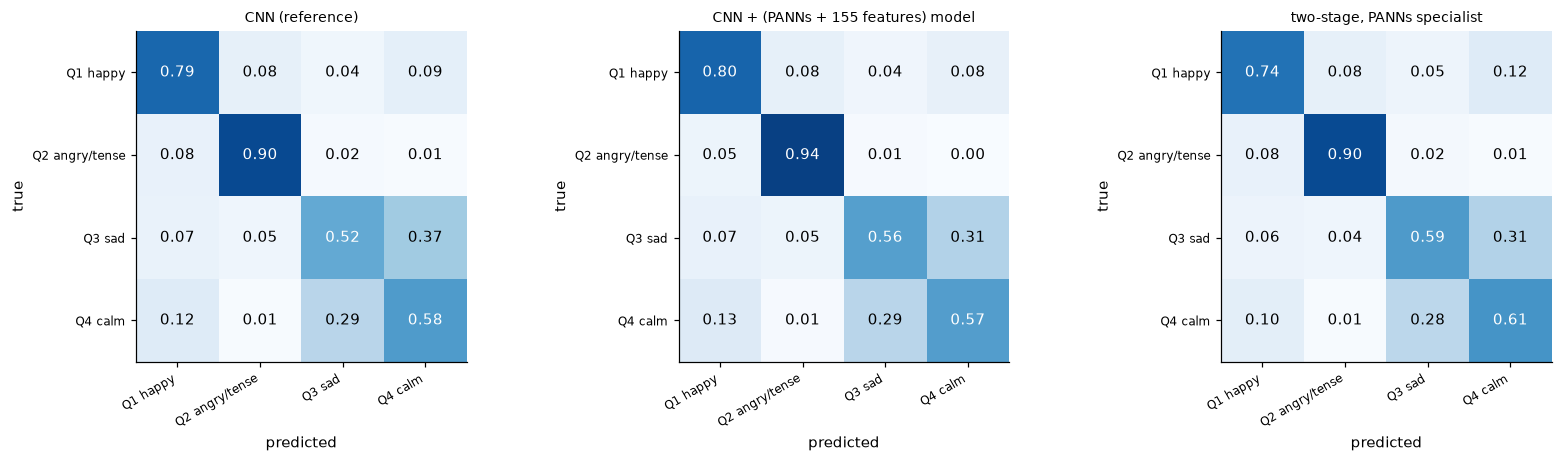

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
pool = all_preds[all_preds.protocol != "A"]
for ax, m in zip(axes, ["cnn", "cnn_fusion_panns_tonal", "two_stage_panns"]):
    s = pool[pool.model == m]
    cm = confusion_matrix(s["true"], s["pred"], labels=QUADRANTS, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(4), [NAMES[q] for q in QUADRANTS], rotation=30, ha="right", fontsize=8)
    ax.set_yticks(range(4), [NAMES[q] for q in QUADRANTS], fontsize=8)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(LABELS[m], fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "04_confusion.png", bbox_inches="tight")
plt.show()

## 5. What the pretrained model "hears": AudioSet mood scores on the training set

PANNs also outputs the probability of each AudioSet class. The figure shows, for the training songs of protocol A, the median score of the seven music-mood classes in each quadrant. It is descriptive only (these scores were not used as features beyond the embedding they come from).

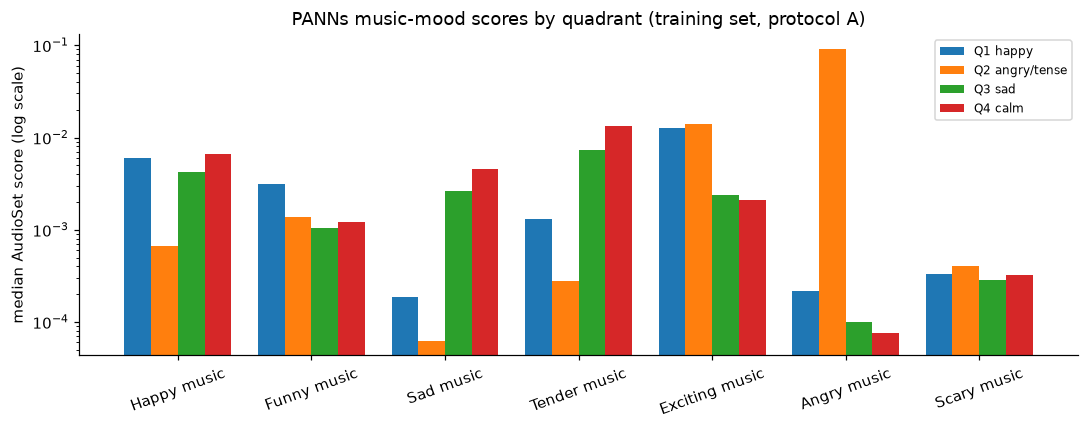

Happy music       0.0200
Funny music       0.0009
Sad music         0.0056
Tender music      0.0081
Exciting music    0.0030
Angry music       0.0093
Scary music       0.0000
Name: epsilon_squared Q3 vs Q4, dtype: float64

In [9]:
mood = pd.read_csv(ROOT / "data" / "embeddings" / "panns_cnn14_audioset_mood.csv", dtype={"Song": str}).set_index("Song")
train = pd.read_csv(ROOT / "data" / "raw" / "MERGE_Audio_Balanced" / "tvt_dataframes" / "tvt_70_15_15" / "tvt_70_15_15_train_audio_balanced.csv", dtype={"Song": str})["Song"]
m_train = mood.loc[mood.index.intersection(train)]
classes = [c for c in m_train.columns if c != "Quadrant"]
med = m_train.groupby("Quadrant")[classes].median()
med.round(5).to_csv(OUT / "05_audioset_mood_median_train.csv")
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(classes))
for k, q in enumerate(QUADRANTS):
    ax.bar(x + (k - 1.5) * 0.2, med.loc[q], 0.2, label=NAMES[q])
ax.set_xticks(x, classes, rotation=20)
ax.set_yscale("log")
ax.set_ylabel("median AudioSet score (log scale)")
ax.set_title("PANNs music-mood scores by quadrant (training set, protocol A)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "05_audioset_mood.png", bbox_inches="tight")
plt.show()
low = m_train[m_train.Quadrant.isin(["Q3", "Q4"])]
eps = {c: (stats.kruskal(low.loc[low.Quadrant == "Q3", c], low.loc[low.Quadrant == "Q4", c]).statistic - 1) / (len(low) - 1) for c in classes}
summary["q3_q4_epsilon_squared_mood"] = {k: round(v, 4) for k, v in eps.items()}
pd.Series(eps, name="epsilon_squared Q3 vs Q4").round(4)

## 6. Summary of the numbers used in the findings

In [10]:
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
summary["selected_per_split"]

{'A': 'cnn_fusion_panns_tonal',
 'B42': 'cnn_fusion_panns_tonal',
 'B43': 'cnn_fusion_panns_tonal',
 'B44': 'cnn_fusion_panns_tonal',
 'B45': 'cnn_fusion_panns_tonal',
 'B46': 'cnn_fusion_panns_tonal'}

## 7. Findings

Numbers are means over the five artist-grouped splits unless stated otherwise; *sad/calm accuracy* is defined in §1.

**1. A two-stage model built on our own features does not reduce the confusion.** With the CNN deciding arousal and a specialist trained only on sad and calm training songs deciding between them, the result is unchanged: macro-F1 0.694 (CNN 0.694), 75.6 sad/calm confusions per split (CNN 75.6), sad/calm accuracy 0.63. On validation the two-stage candidates looked 1–3 points better, but the gain did not carry over to the test sets, which is the expected effect of choosing among many candidates on about 480 validation songs. The best single hand-crafted feature explains about 3 % of the sad/calm difference (ε² = 0.027). The structure of the model is therefore not the bottleneck: the information that separates sad from calm music is weak in the features and in the spectrogram the CNN sees.

**2. Representations from a pretrained audio model add that information.** Adding the 2,048-dimensional PANNs embedding to our 155 features and training an SVM gives 0.711 ± 0.020, already above the CNN (0.694 ± 0.018), with fewer sad/calm confusions (68.8) and higher F1 on both Q3 (0.585) and Q4 (0.592). The embedding alone gives 0.697.

**3. The best overall model combines the CNN with the PANNs-based SVM.** Fusing their probabilities (weight chosen on validation, between 0.3 and 0.8 for the CNN) was the variant with the highest validation macro-F1 on **all six** splits, and reaches 0.713 ± 0.023 on unseen artists (+0.019 over the CNN; accuracy 71.8 %). Pooled over the artist splits it is right where the CNN is wrong on 220 songs and the opposite on 175 (McNemar p = 0.027). On the official split it reaches 0.726, above the 68.52 % reported by the dataset authors for audio only; this is a single split and is reported as such. Its sad/calm improvement is moderate (69.4 confusions per split, F1 Q3 0.592, Q4 0.582) and not significant on the sad and calm songs alone (p = 0.31).

**4. The model aimed at the sad/calm problem is the two-stage model with a PANNs specialist.** Keeping the CNN's arousal decision and deciding sad vs calm with a specialist trained on the PANNs embedding gives the largest sad/calm gain: F1 Q3 0.558 → 0.607, F1 Q4 0.567 → 0.597, confusions 75.6 → 68.0 per split, sad/calm accuracy 0.627 → 0.671. On the sad and calm test songs it is right where the CNN is wrong on 133 songs and the opposite on 75 (p = 0.0001), the only clearly significant improvement on this pair. Its overall macro-F1 (0.709) is close to the fusion's but it was not the variant with the best validation macro-F1 on any split, so it is reported as the targeted result rather than as the selected model; the significance above is measured on the test sets and should be read with that in mind.

**5. What the pretrained model knows is in its representation, not in its mood labels.** PANNs' own *Sad music* and *Tender music* scores barely separate Q3 from Q4 on the training set (ε² 0.006 and 0.008); the general 2,048-dimensional embedding, learned from about two million clips, is what carries the useful information. A model trained on far more audio than the 2,264 training songs here captures cues of texture and timbre that neither our features nor a CNN trained from scratch can learn from this dataset alone.

**6. Sad vs calm remains the hardest pair.** Even the best model confuses about 30 % of the sad and calm songs (sad/calm accuracy 0.67, against 0.63 before and 0.50 for chance). The improvement is real but partial, consistent with the dataset authors' observation that separating Q3 from Q4 from audio is far from solved and that lyrics help most for these quadrants.

**Decision (D19).** The final model reported in the thesis and used in the interface is the fusion of the CNN with the SVM on PANNs embedding + 155 features, selected on validation on every split. The two-stage model with a PANNs specialist is reported as the answer to the sad/calm question. The CNN and the SVM on hand-crafted features remain the reference models of the two families compared in the thesis.